# 02 — Pré-processamento e Engenharia de Atributos

**Objetivo:** Limpar o dataset, corrigir tipos de dados, criar novas variáveis
(ex.: tempo de espera em dias, faixas etárias), tratar o desbalanceamento de classes
e gerar o conjunto final de treino/teste pronto para modelagem.

## 1. Limpeza (issue #7)

Regras aplicadas em `src/data.py`, a partir dos problemas mapeados no
[dicionário de dados](../docs/dicionario_dados.md):

- Renomear colunas para snake_case (`Hipertension` → `hypertension`, `No-show` → `no_show`, etc.).
- Converter `scheduled_day`/`appointment_day` para datetime e `patient_id` para string.
- Remover idades fora de 0–100 anos (1 negativa, 7 acima de 100 — quatro delas
  do mesmo paciente com 115, quase certamente erro de registro).
- Remover consultas cuja data é anterior à data do agendamento (5 linhas).
- Remover duplicatas que repetem tudo menos `appointment_id`, mantendo a
  primeira ocorrência. Grupos em que o alvo diverge entre as duplicatas são
  removidos por inteiro, pois não há como saber qual rótulo é o correto.
- Converter flags binárias para bool e o alvo `no_show` para 1/0 (1 = faltou).

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import data
import features

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

raw = data.load_raw('../data/raw/KaggleV2-May-2016.csv')
print('Bruto:', raw.shape)

Bruto: (110527, 14)


In [2]:
# Quantas linhas cada regra remove (na mesma ordem em que clean() aplica,
# para não contar duas vezes linhas que caem em mais de um critério)
r = raw.rename(columns=data.RENAME_COLUMNS)
sched = pd.to_datetime(r['scheduled_day'], utc=True).dt.tz_localize(None)
appt = pd.to_datetime(r['appointment_day'], utc=True).dt.tz_localize(None).dt.normalize()
key = [c for c in r.columns if c not in ('appointment_id', 'no_show')]

m_idade = ~r['age'].between(0, data.MAX_AGE)
m_data = (appt < sched.dt.normalize()) & ~m_idade
m_divergente = (r.groupby(key)['no_show'].transform('nunique') > 1) & ~m_idade & ~m_data
m_dup = r.duplicated(subset=key + ['no_show']) & ~m_idade & ~m_data & ~m_divergente

pd.Series({
    'idade fora de 0–100': m_idade.sum(),
    'consulta antes do agendamento': m_data.sum(),
    'duplicata com alvo divergente (grupo inteiro)': m_divergente.sum(),
    'duplicata idêntica (mantém a 1ª)': m_dup.sum(),
    'total removido': (m_idade | m_data | m_divergente | m_dup).sum(),
})

idade fora de 0–100                                8
consulta antes do agendamento                      5
duplicata com alvo divergente (grupo inteiro)     28
duplicata idêntica (mantém a 1ª)                 617
total removido                                   658
dtype: int64

In [3]:
df = data.clean(raw)
print('Limpo:', df.shape)
df.dtypes

Limpo: (109869, 14)


patient_id                    str
appointment_id              int64
gender                   category
scheduled_day      datetime64[us]
appointment_day    datetime64[us]
age                         int64
neighbourhood            category
bolsa_familia                bool
hypertension                 bool
diabetes                     bool
alcoholism                   bool
handicap                    int64
sms_received                 bool
no_show                      int8
dtype: object

In [4]:
df.head()

,patient_id,appointment_id,gender,scheduled_day,appointment_day,age,neighbourhood,bolsa_familia,hypertension,diabetes,alcoholism,handicap,sms_received,no_show
0,29872499824296,5642903,F,2016-04-29 18:38:08,2016-04-29,62,JARDIM DA PENHA,False,True,False,False,0,False,0
1,558997776694438,5642503,M,2016-04-29 16:08:27,2016-04-29,56,JARDIM DA PENHA,False,False,False,False,0,False,0
2,4262962299951,5642549,F,2016-04-29 16:19:04,2016-04-29,62,MATA DA PRAIA,False,False,False,False,0,False,0
3,867951213174,5642828,F,2016-04-29 17:29:31,2016-04-29,8,PONTAL DE CAMBURI,False,False,False,False,0,False,0
4,8841186448183,5642494,F,2016-04-29 16:07:23,2016-04-29,56,JARDIM DA PENHA,False,True,True,False,0,False,0


## 2. Engenharia de atributos (issue #7)

Dois atributos novos em `src/features.py::build_features`:

- `waiting_days`: dias de espera entre a data do agendamento e a data da
  consulta (por dia, ignorando a hora). É o preditor mais promissor: na EDA,
  agendamentos para o próprio dia faltam 4,6%, contra 28,5% com espera.
- `appointment_weekday`: dia da semana da consulta (0 = segunda, 5 = sábado).
  Não há consultas em domingo e quase nenhuma em sábado.

In [5]:
feat = features.build_features(df)
print(feat.shape)
feat[['waiting_days', 'appointment_weekday']].describe()

(109869, 16)


,waiting_days,appointment_weekday
count,109869.000000,109869.000000
mean,10.155649,1.857803
std,15.251384,1.370997
min,0.000000,0.000000
25%,0.000000,1.000000
50%,4.000000,2.000000
75%,15.000000,3.000000
max,179.000000,5.000000


In [6]:
# Sanity check das novas colunas
assert feat['waiting_days'].min() >= 0
print('Agendamentos no mesmo dia:', (feat['waiting_days'] == 0).sum())
print('Taxa de falta (mesmo dia):', round(feat.loc[feat['waiting_days'] == 0, 'no_show'].mean(), 3))
print('Taxa de falta (com espera):', round(feat.loc[feat['waiting_days'] > 0, 'no_show'].mean(), 3))

dias = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
taxa = feat.groupby('appointment_weekday', observed=True)['no_show'].agg(['mean', 'count'])
taxa.index = [dias[i] for i in taxa.index]
taxa

Agendamentos no mesmo dia: 38488
Taxa de falta (mesmo dia): 0.046
Taxa de falta (com espera): 0.284


,mean,count
seg,0.205220,22566
ter,0.199914,25501
qua,0.196137,25732
qui,0.192731,17169
sex,0.211536,18862
sáb,0.230769,39


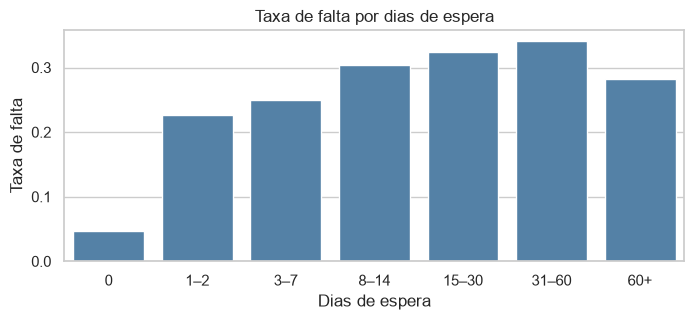

In [7]:
# Taxa de falta sobe rápido com os primeiros dias de espera
fig, ax = plt.subplots(figsize=(8, 3))
faixas = pd.cut(feat['waiting_days'], bins=[-1, 0, 2, 7, 14, 30, 60, 200],
                labels=['0', '1–2', '3–7', '8–14', '15–30', '31–60', '60+'])
taxa_espera = feat.groupby(faixas, observed=True)['no_show'].mean()
sns.barplot(x=taxa_espera.index, y=taxa_espera.values, ax=ax, color='steelblue')
ax.set(title='Taxa de falta por dias de espera', xlabel='Dias de espera', ylabel='Taxa de falta')
plt.show()

## 3. Exportação

Dataset limpo e com os novos atributos salvo em `data/processed/clean.parquet`
(pasta ignorada no git). É a base para o baseline (issue #8) e para as
próximas etapas de atributos, como histórico do paciente (issue #9) e
codificação de categóricas.

In [8]:
data.save_processed(feat, '../data/processed/clean.parquet')
final = pd.read_parquet('../data/processed/clean.parquet')
print('Salvo:', final.shape)
final.head()

Salvo: (109869, 16)


,patient_id,appointment_id,gender,scheduled_day,appointment_day,age,neighbourhood,bolsa_familia,hypertension,diabetes,alcoholism,handicap,sms_received,no_show,waiting_days,appointment_weekday
0,29872499824296,5642903,F,2016-04-29 18:38:08,2016-04-29,62,JARDIM DA PENHA,False,True,False,False,0,False,0,0,4
1,558997776694438,5642503,M,2016-04-29 16:08:27,2016-04-29,56,JARDIM DA PENHA,False,False,False,False,0,False,0,0,4
2,4262962299951,5642549,F,2016-04-29 16:19:04,2016-04-29,62,MATA DA PRAIA,False,False,False,False,0,False,0,0,4
3,867951213174,5642828,F,2016-04-29 17:29:31,2016-04-29,8,PONTAL DE CAMBURI,False,False,False,False,0,False,0,0,4
4,8841186448183,5642494,F,2016-04-29 16:07:23,2016-04-29,56,JARDIM DA PENHA,False,True,True,False,0,False,0,0,4
